In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, j0, j1, jv, jvp
from matplotlib import colors
from scipy.integrate import trapezoid
from scipy.signal import savgol_filter
from scipy.interpolate import make_smoothing_spline

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors

import csv
import os
import time

from transmission_maps import *

from matplotlib.colors import LogNorm

In [3]:
# Setup for the instrument
baseline =10 # [m]
q = 6 # ratio of the imaging baseline to the nulling baseline

xk = baseline/2
yk = q*baseline/2
lambda_ref = 10e-6 # 10 microns

fov_as = 0.4 # [arcsec]
fov_rad =  fov_as * (np.pi / 180) / 3600 # [rad]

rot_angle = 20 # [deg]

Npix = 80
alpha = np.linspace(-fov_as, fov_as, Npix)
beta = np.linspace(-fov_as, fov_as, Npix)

## Image Generation

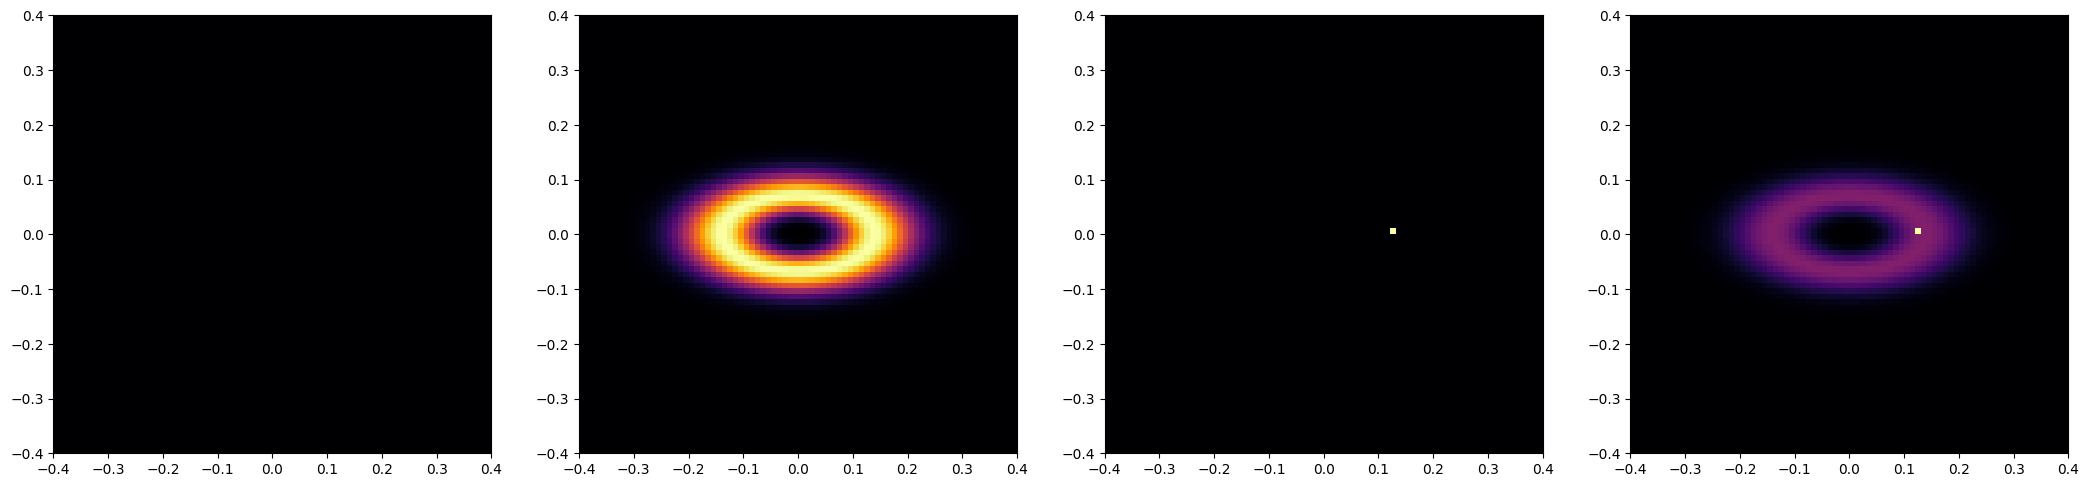

In [4]:

ALPHA, BETA = np.meshgrid(alpha, beta) # [as]
IM = np.zeros_like(ALPHA)

# Star 
IM_star = IM.copy()
IM_star[int(1/2*Npix), int(1/2*Npix)] = 0

# Exozodi
inc = 60 * (np.pi/180)
phi = 0 * (np.pi/180)
ALPHA_rot = ALPHA * np.cos(phi) + BETA * np.sin(phi)
BETA_rot = 1/np.cos(inc) * (-ALPHA * np.sin(phi) + BETA * np.cos(phi))
R_rot2 = ALPHA_rot**2 + BETA_rot**2
sig2 = 0.1**2

IM_exozodi = IM.copy()
IM_exozodi = 1e3*(R_rot2/sig2)**2 *np.exp( -R_rot2 / sig2)

# Planet
IM_planet = IM.copy()
X_planet = int(1/2*Npix)
Y_planet = int(13/20*Npix)
IM_planet[X_planet, Y_planet] = 1000
pos_planet_as = np.array([alpha[X_planet], beta[Y_planet]])
pos_planet_rad = np.array([alpha[X_planet] *  (np.pi / 180) / 3600 , beta[Y_planet] *  (np.pi / 180) / 3600 ])
sep_planet_as = np.linalg.norm(pos_planet_as)
sep_planet_rad = np.linalg.norm(pos_planet_rad)


# Plot
fig, ax = plt.subplots(1, 4, figsize=(26, 8))
vmin = min(np.min(IM_star), np.min(IM_exozodi), np.min(IM_planet))
vmax = max(np.max(IM_star), np.max(IM_planet + IM_exozodi))

ax[0].imshow(IM_star, origin = 'lower', cmap='inferno',  extent=(min(beta), max(beta), min(alpha), max(alpha)))
ax[1].imshow(IM_exozodi, origin = 'lower', cmap='inferno',  extent=(min(beta), max(beta), min(alpha), max(alpha)))
ax[2].imshow(IM_planet, origin = 'lower', cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)))
ax[3].imshow(IM_star + IM_exozodi + IM_planet, origin = 'lower', cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)))
#cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

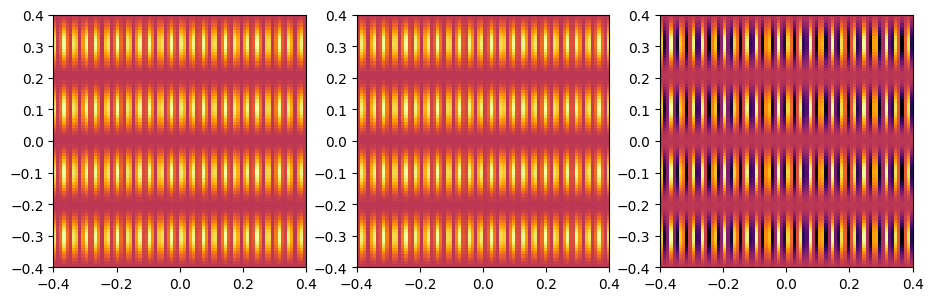

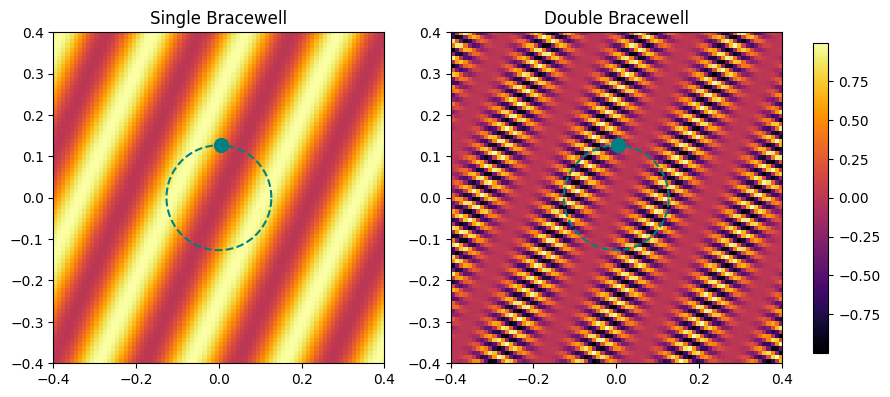

In [5]:
lambda_ref = 10e-6

# Double Bracewell Transmission Map - Manual Calculation
V1 = Vk(pos=(xk, yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
V2 = Vk(pos=(-xk, yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
V3 = Vk(pos=(xk, -yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)
V4 = Vk(pos=(-xk, -yk), lambda_ref=lambda_ref, alpha=alpha, beta=beta)

D1 = 1/np.sqrt(4)*(V1 + np.exp(1j*np.pi)*V2)
D2 = 1/np.sqrt(4)*(V3 + np.exp(1j*np.pi)*V4)

O1 = 1/np.sqrt(4)*(D1 + np.exp(1j*np.pi/2)*D2)  
O2 = 1/np.sqrt(4)*(D1 - np.exp(1j*np.pi/2)*D2)

TDBW = np.abs(O1)**2 - np.abs(O2)**2


# Single Bracewell Transmission Map
V1 = Vk(pos=(xk, 0), lambda_ref=lambda_ref) 
V2 = Vk(pos=(-xk, 0), lambda_ref=lambda_ref)

D1 = 1/2*(V1 + np.exp(1j*np.pi)*V2)
D2 = 1/2*(V1 - np.exp(1j*np.pi)*V2)



vmin = np.min(np.abs(O1)**2 - np.abs(O2)**2)
vmax = np.max(np.abs(O1)**2 - np.abs(O2)**2)
plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(np.abs(O1)**2, vmin = vmin, vmax = vmax, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap='inferno')
plt.subplot(1, 4, 2)
plt.imshow(np.abs(O2)**2, vmin = vmin, vmax = vmax, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap='inferno')
plt.subplot(1, 4, 3)
plt.imshow(np.abs(O1)**2 - np.abs(O2)**2, vmin = vmin, vmax = vmax, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap='inferno')



# Star on sky
T_SBW = transmission_map_SBW(baseline = baseline, rot_angle=rot_angle, lambda_ref=lambda_ref, alpha=alpha, beta=beta) #np.abs(D1)**2
T_DBW = transmission_map_DBW(baseline = baseline, q = q, rot_angle=rot_angle, lambda_ref=lambda_ref, alpha=alpha, beta=beta) #np.abs(D1)**2
vmin = min(np.min(T_SBW), np.min(T_DBW))
vmax = max(np.max(T_SBW), np.max(T_DBW))
norm = colors.Normalize(vmin=vmin, vmax=vmax)

phi = np.linspace(0, 2*np.pi, 100)
x, y = sep_planet_as * np.cos(phi), sep_planet_as * np.sin(phi)

fig, ax = plt.subplots(1,2, figsize=(10,5))
images = []
images.append(ax[0].imshow(T_SBW,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)), norm=norm))
ax[0].plot(x, y, color='teal', label='Planet Orbit', linestyle='--')
ax[0].scatter(pos_planet_as[0], pos_planet_as[1], color='teal', label='Planet', s=100)
ax[0].set_title('Single Bracewell')

images.append(ax[1].imshow(T_DBW,cmap='inferno', extent=(min(beta), max(beta), min(alpha), max(alpha)), norm=norm))
ax[1].plot(x, y, color='teal', label='Planet Orbit', linestyle='--')
ax[1].scatter(pos_planet_as[0], pos_planet_as[1], color='teal', label='Planet', s=100)
ax[1].set_title('Double Bracewell')


fig.colorbar(images[0], ax=ax, orientation='vertical', fraction=0.02, pad=0.04)


## Signal Processing

Text(0.5, 1.0, 'Planet Signal in Double Bracewell')

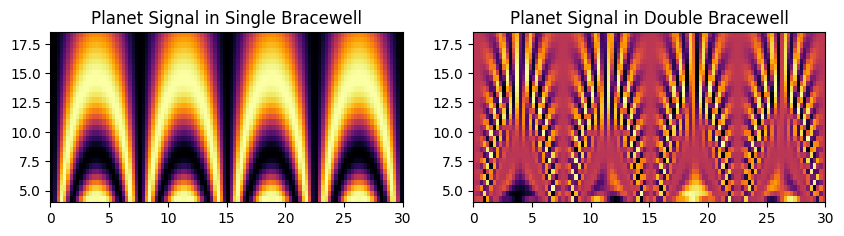

In [6]:
time = 30 * 3600 # [s]
read_time = 1000 #[s]
N = int(time / read_time)

t = np.linspace(0, time, N)

Omega = (2 / time) * 2 * np.pi # 60 rotations in 42 day [rad/s]
R = 20
lambda_min = 4e-6
lambda_max = 18.5e-6
lambdas = np.logspace(np.log10(lambda_min), np.log10(lambda_max), int(R * np.log(lambda_max/lambda_min) + 0.5), base = 10)
# lambdas = np.linspace(lambda_min, lambda_max, int(R * np.log(lambda_max/lambda_min)))



# Signal of a planet at (angsep, 0)
signal_planet_sbw = point_signal_SBW(t, alpha = pos_planet_as[0], beta = pos_planet_as[1], baseline = baseline, lamda_ref=lambdas, Omega = Omega)
signal_planet_dbw = point_signal_DBW(t, alpha = pos_planet_as[0], beta = pos_planet_as[1], baseline = baseline, lamda_ref=lambdas, q=q, Omega = Omega)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(signal_planet_sbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), cmap='inferno', origin = 'lower')
ax[1].imshow(signal_planet_dbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
ax[0].set_title('Planet Signal in Single Bracewell')
ax[1].set_title('Planet Signal in Double Bracewell')


### Time dependent Transmission Map for the signal of the entire field of view

In [7]:
# time and wavelength dependent transmission map
T_SBW_lambda_scenery = point_signal_SBW(t, ALPHA, BETA, baseline, lamda_ref=lambdas, Omega = Omega)
T_DBW_lambda_scenery = point_signal_DBW(t, ALPHA, BETA, baseline, lamda_ref=lambdas, Omega = Omega, q=q)

In [8]:
# Time and wavelength dependent signal 
signal_planet_sbw = np.sum(T_SBW_lambda_scenery * (IM_star + IM_planet)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi + IM_planet)
signal_exozodi_sbw = np.sum(T_SBW_lambda_scenery * (IM_star + IM_exozodi)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi)
signal_both_sbw = np.sum(T_SBW_lambda_scenery * (IM_star + IM_exozodi + IM_planet)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi + IM_planet)

signal_planet_dbw = np.sum(T_DBW_lambda_scenery * (IM_star + IM_planet)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi + IM_planet)
signal_exozodi_dbw = np.sum(T_DBW_lambda_scenery * (IM_star + IM_exozodi)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi)
signal_both_dbw = np.sum(T_DBW_lambda_scenery * (IM_star + IM_exozodi + IM_planet)[None, None, :, :], axis=(2,3)) #- np.sum(IM_star + IM_exozodi + IM_planet)

Text(0.5, 1.0, 'Signal with Both')

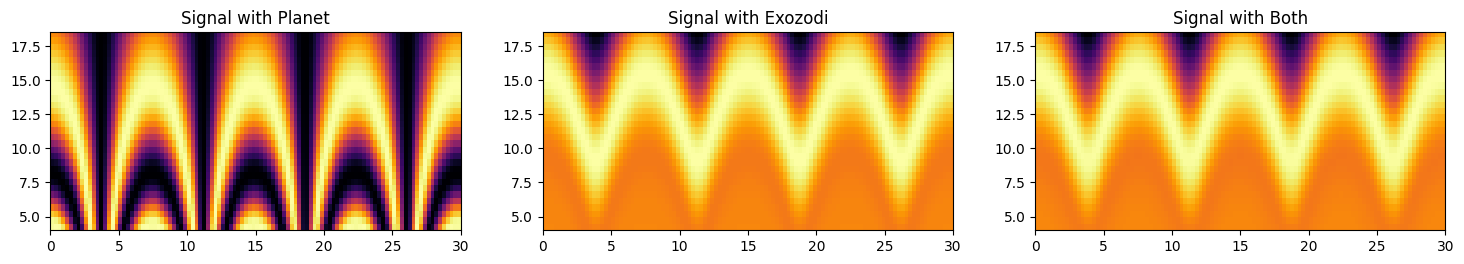

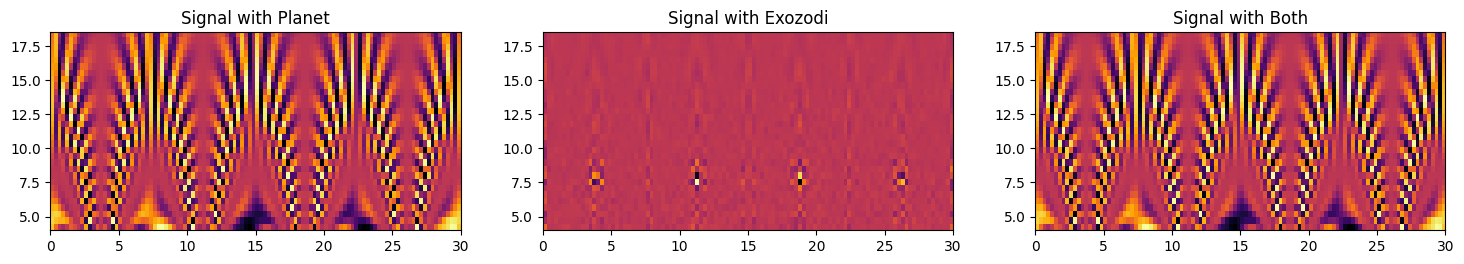

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(np.min(signal_planet_sbw), np.min(signal_exozodi_sbw), np.min(signal_both_sbw))
vmax = max(np.max(signal_planet_sbw), np.max(signal_exozodi_sbw), np.max(signal_both_sbw))
ax[0].imshow(signal_planet_sbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
ax[1].imshow(signal_exozodi_sbw,  extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), cmap='inferno', origin = 'lower')
ax[2].imshow(signal_both_sbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
ax[0].set_title('Signal with Planet')
ax[1].set_title('Signal with Exozodi')
ax[2].set_title('Signal with Both')

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(np.min(signal_planet_dbw), np.min(signal_exozodi_dbw), np.min(signal_both_dbw))
vmax = max(np.max(signal_planet_dbw), np.max(signal_exozodi_dbw), np.max(signal_both_dbw))
ax[0].imshow(signal_planet_dbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
ax[1].imshow(signal_exozodi_dbw,  extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6), cmap='inferno', origin = 'lower')
ax[2].imshow(signal_both_dbw, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
ax[0].set_title('Signal with Planet')
ax[1].set_title('Signal with Exozodi')
ax[2].set_title('Signal with Both')


In [10]:
# Image with planet - averaged over time 

def cross_corr_coeff(signal, template, centered = True):
    S = signal.copy()
    T = template.copy() 
    if centered:
        S -= np.mean(signal, axis = 1)[:, None] # average along time axis
        T -= np.mean(template, axis = 1)[:,None,:,:] # average along time axis

    return np.sum(T * S[:, :, None, None], axis = 1) / np.linalg.norm(T, axis = 1) / np.linalg.norm(S, axis = 1)[:, None, None]

def cross_corr_coeff_merged(signal, template, centered = True):
    S = signal.copy()
    T = template.copy() 
    if centered:
        S   -=np.mean(signal, axis = 1)[:, None] # average along time axis
        T -= np.mean(template, axis = 1)[:,None,:,:] # average along time axis

    return np.sum(T * S[:, :, None, None], axis = (0,1)) / np.linalg.norm(T, axis = (0,1)) / np.linalg.norm(S)

In [11]:
def combined_plot(signal_planet, signal_exozodi, signal_both, T_scenery, centered = True, vmin = None, vmax = None,  cmap = 'viridis'):



    proj_planet =  cross_corr_coeff(signal_planet, T_scenery, centered = centered) 
    proj_exozodi = cross_corr_coeff(signal_exozodi, T_scenery, centered = centered)
    proj_both = cross_corr_coeff(signal_both, T_scenery, centered = centered)

    # Image with planet - averaged over time and wavelength
    proj_planet_merged = cross_corr_coeff_merged(signal_planet, T_scenery, centered = centered)
    proj_exozodi_merged =cross_corr_coeff_merged(signal_exozodi, T_scenery, centered = centered) 
    proj_both_merged = cross_corr_coeff_merged(signal_both, T_scenery, centered = centered)


    fig, ax = plt.subplots(3, 7, figsize = (15, 8))
    N_l = ax.shape[1]-2
    step = int(len(lambdas)/N_l)
    print(N_l, step)
    for i in range(N_l):
        ax[0, i].imshow(proj_planet[i*step,:,:], extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap, vmin=vmin, vmax=vmax)
        ax[1, i].imshow(proj_exozodi[i*step,:,:], extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
        ax[2, i].imshow(proj_both[i*step,:,:], extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
        ax[0, i].set_title(rf"$\lambda$ = {np.round(1e6*lambdas[i*step],2)} $\mu m$")
    ax[0, -2].imshow(proj_planet_merged, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
    ax[1, -2].imshow(proj_exozodi_merged, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
    ax[2, -2].imshow(proj_both_merged, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
    ax[0, -1].imshow(IM_planet, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = 'inferno')
    ax[1, -1].imshow(IM_exozodi, extent=(-fov_as, fov_as, -fov_as, fov_as),cmap = 'inferno')
    ax[2, -1].imshow(IM_planet + IM_exozodi, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = 'inferno')
    ax[0, -2].set_title(r"All $\lambda$")
    ax[0, -1].set_title(r"Target Image")
    for i in range(ax.shape[0]):
        for j in range(ax.shape[1]):
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])
    plt.show()
    plt.close()


5 6


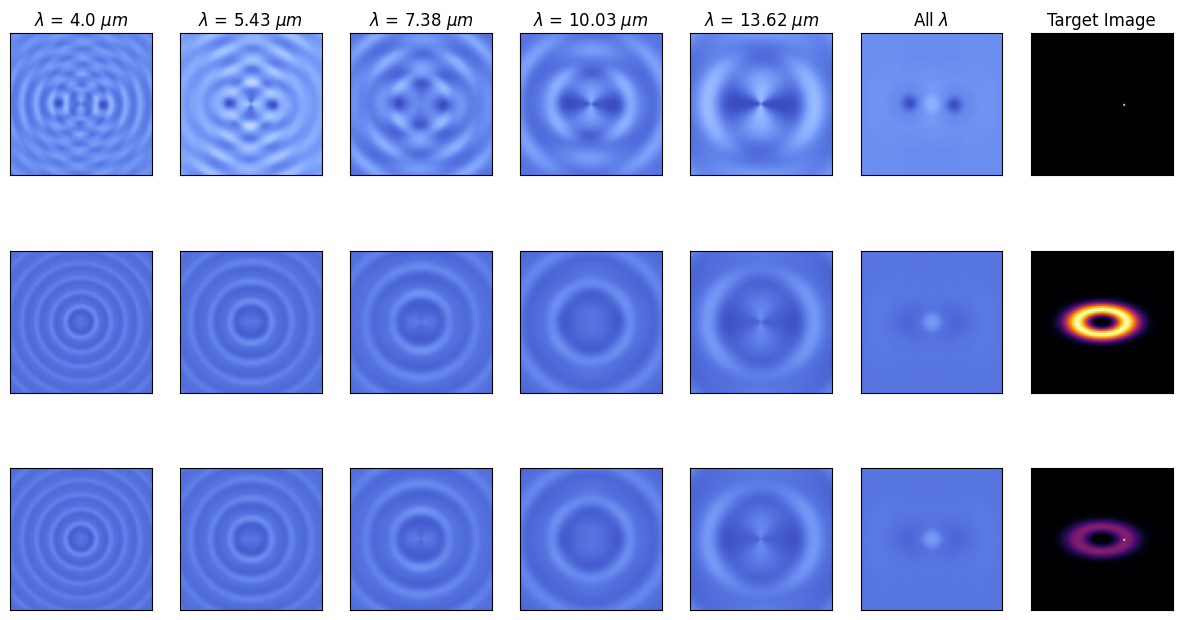

5 6


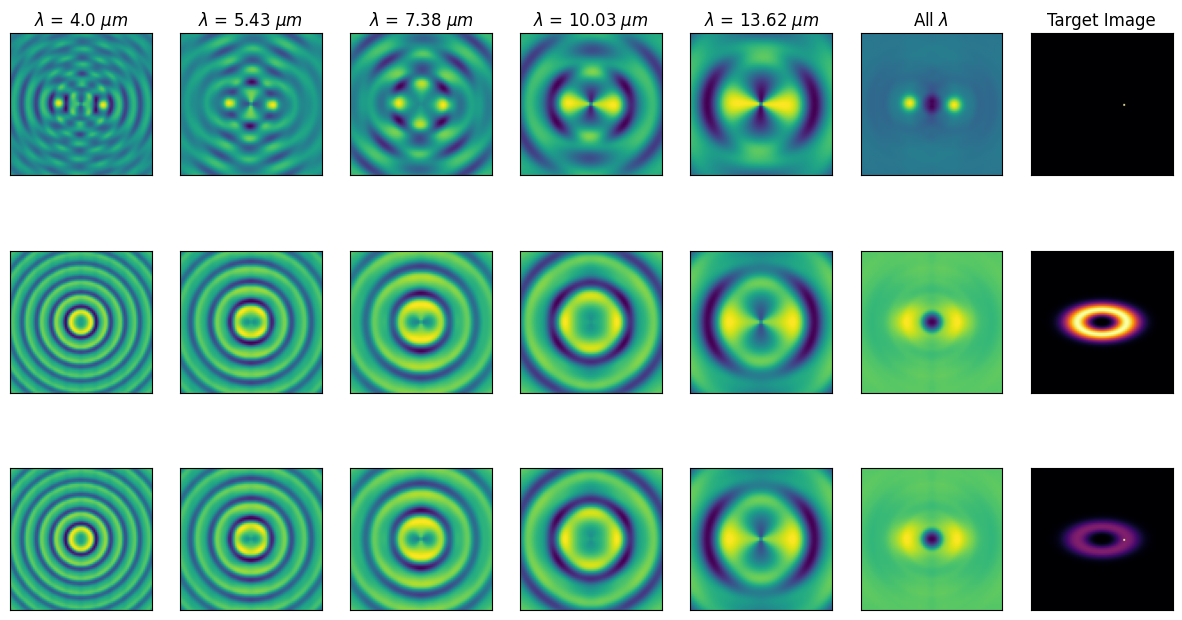

In [12]:
combined_plot(signal_planet_sbw, signal_exozodi_sbw, signal_both_sbw, T_SBW_lambda_scenery, centered=False, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(signal_planet_sbw, signal_exozodi_sbw, signal_both_sbw, T_SBW_lambda_scenery, centered =False)


5 6


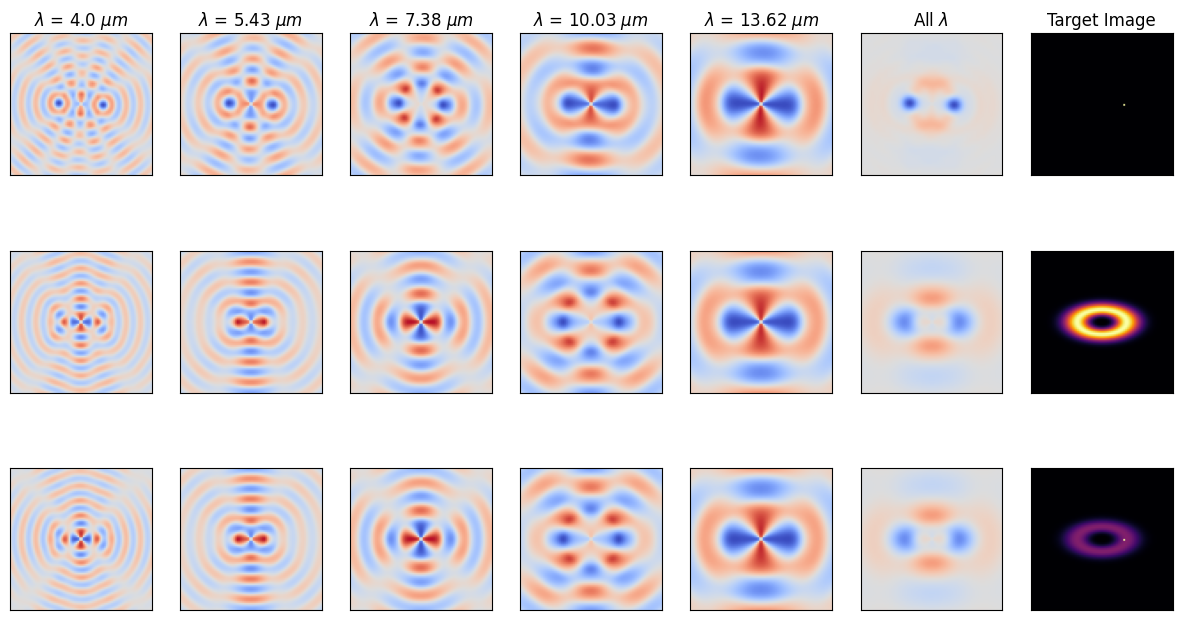

5 6


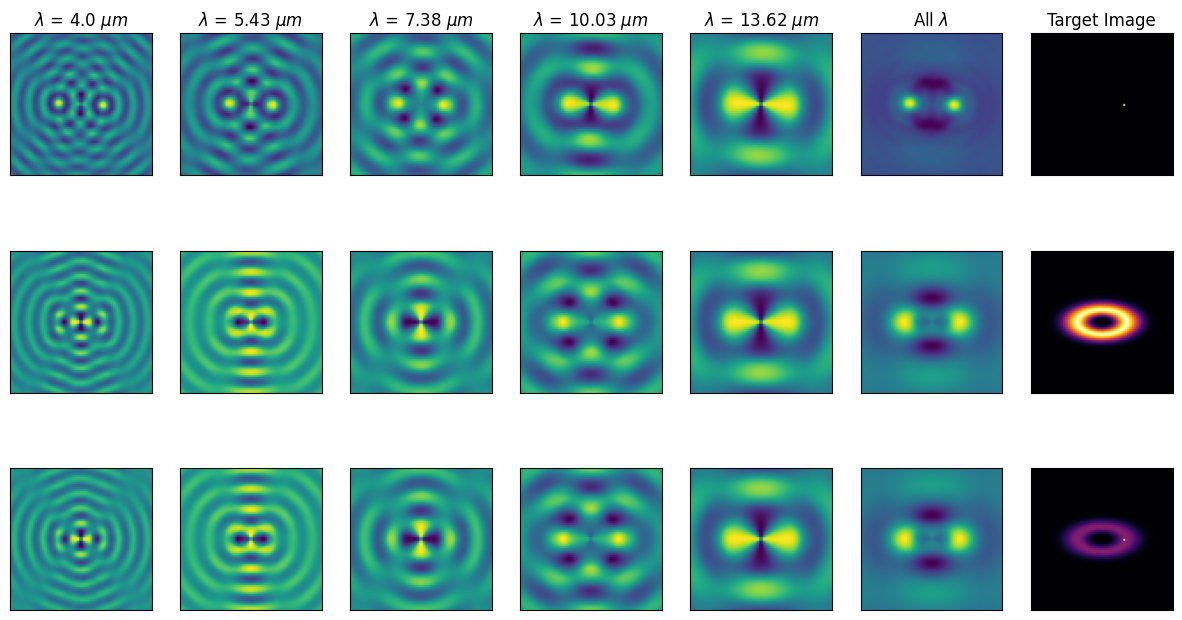

In [13]:
combined_plot(signal_planet_sbw, signal_exozodi_sbw, signal_both_sbw, T_SBW_lambda_scenery, centered=True, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(signal_planet_sbw, signal_exozodi_sbw, signal_both_sbw, T_SBW_lambda_scenery, centered =True)


5 6


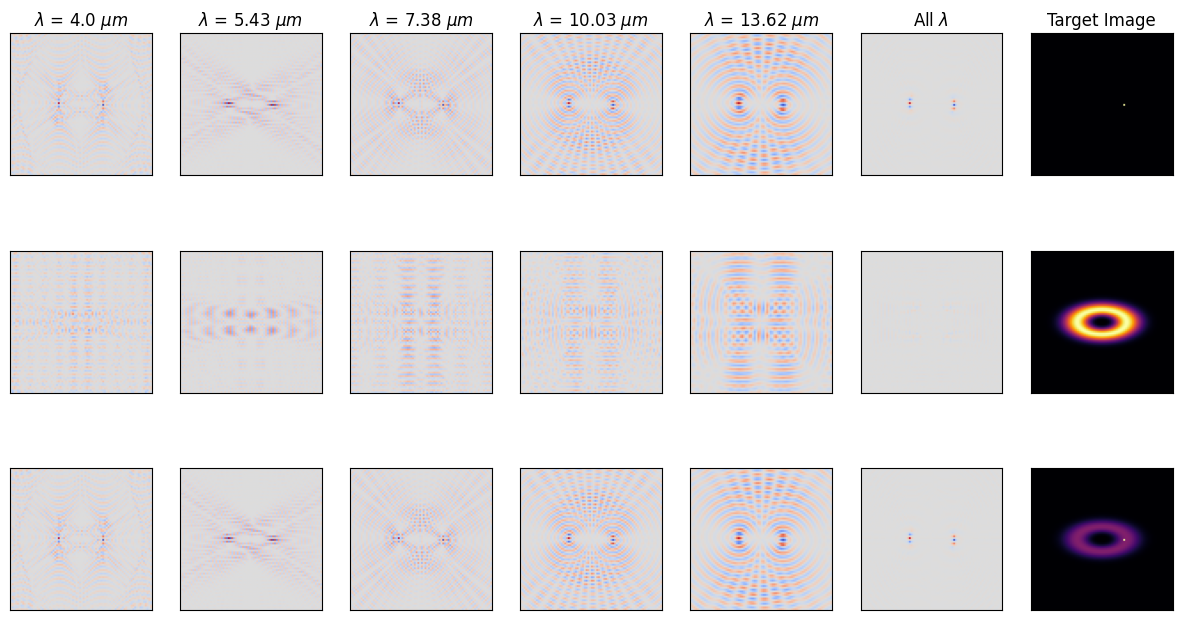

5 6


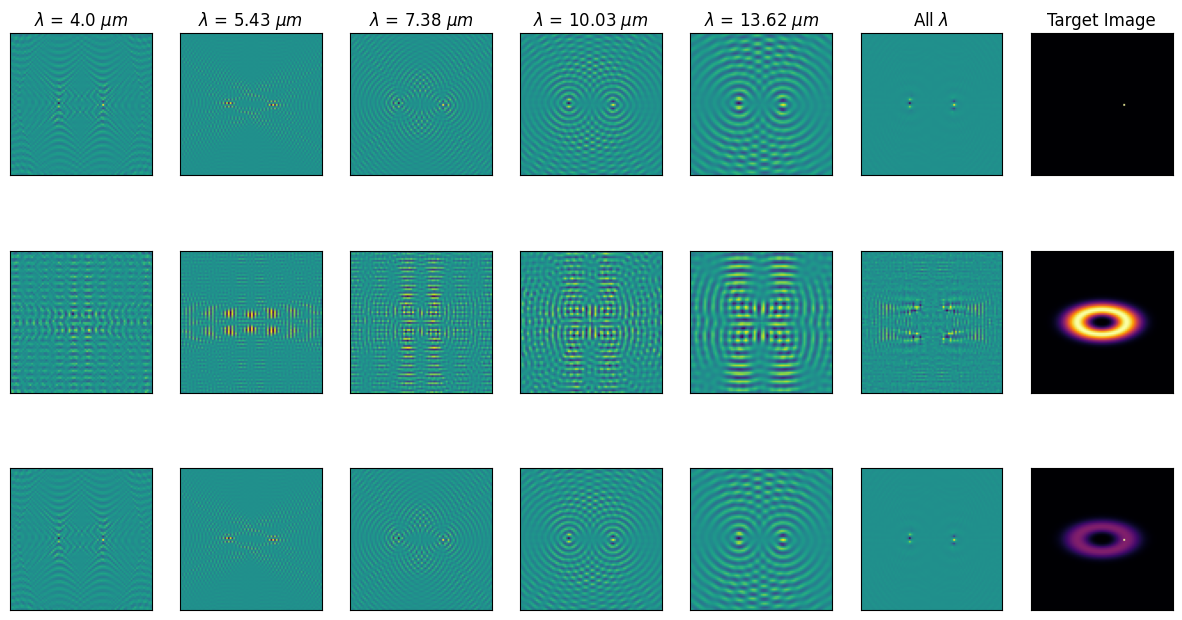

In [14]:
combined_plot(signal_planet_dbw, signal_exozodi_dbw, signal_both_dbw, T_DBW_lambda_scenery, centered=False, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(signal_planet_dbw, signal_exozodi_dbw, signal_both_dbw, T_DBW_lambda_scenery, centered =False)


5 6


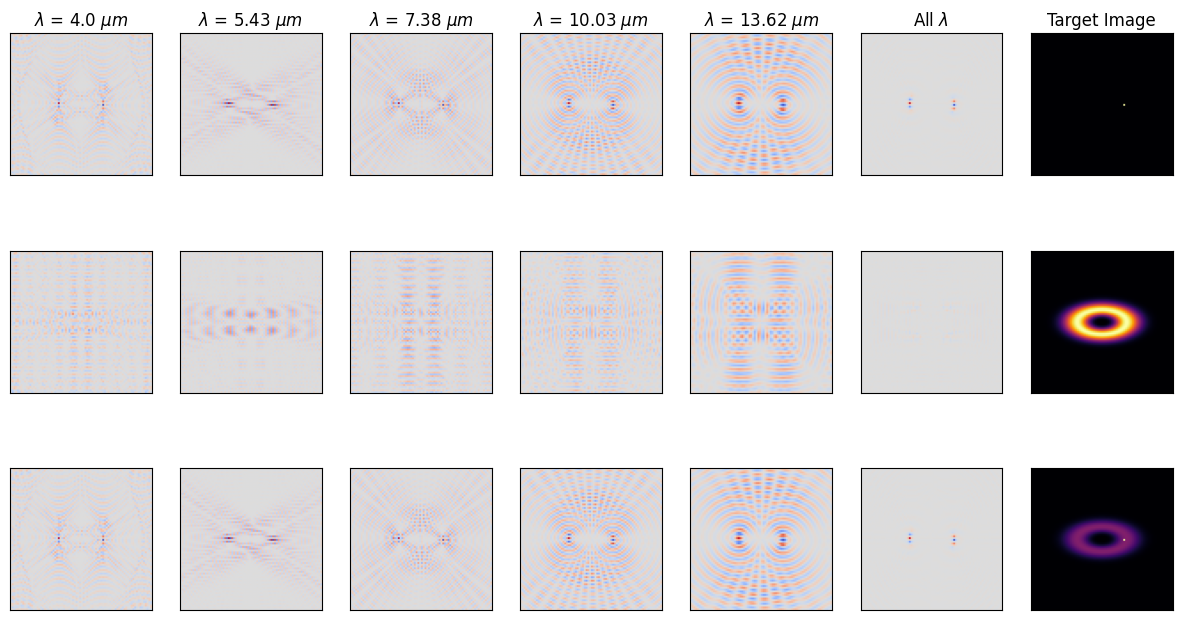

5 6


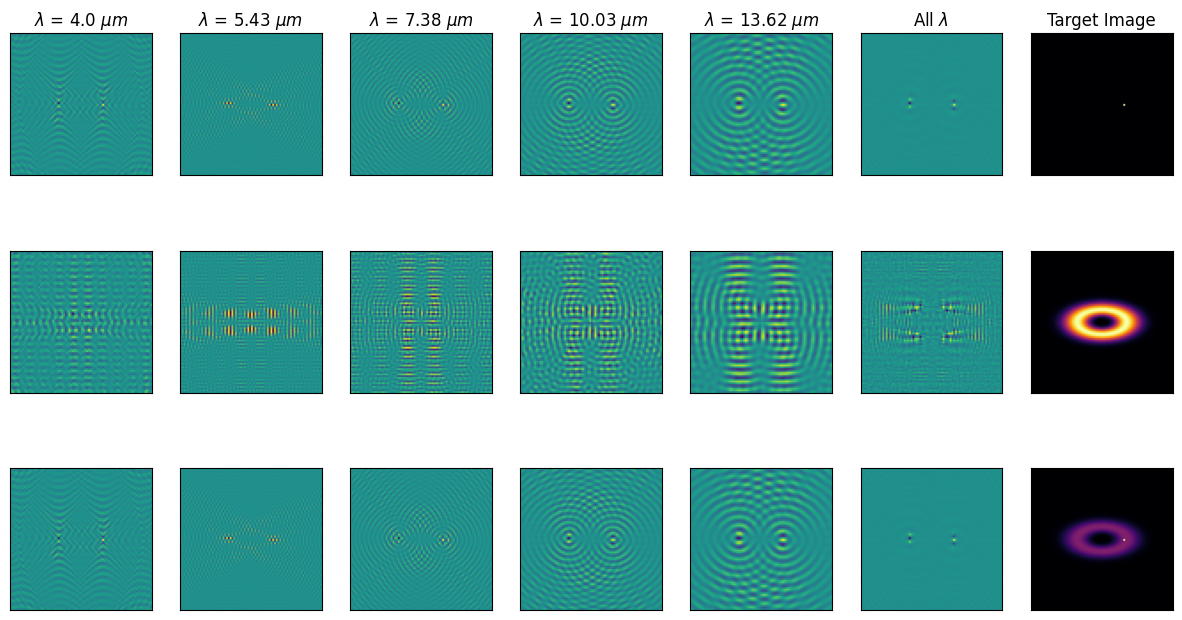

In [15]:
combined_plot(signal_planet_dbw, signal_exozodi_dbw, signal_both_dbw, T_DBW_lambda_scenery, centered=True, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(signal_planet_dbw, signal_exozodi_dbw, signal_both_dbw, T_DBW_lambda_scenery, centered =True)


In [16]:
#row, col = np.unravel_index(np.argmin(proj_planet_merged_sbw), proj_planet_merged_sbw.shape)
#proj_planet_merged_sbw[row, col]

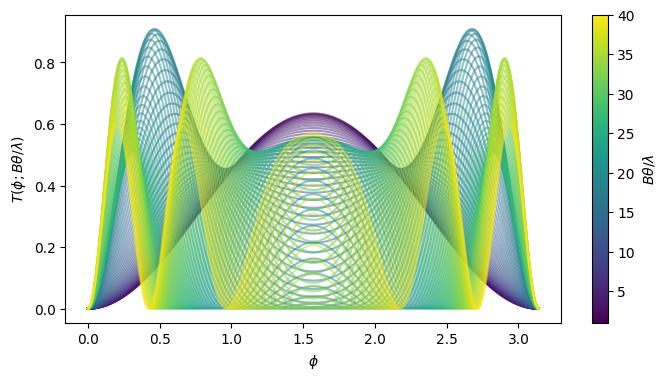

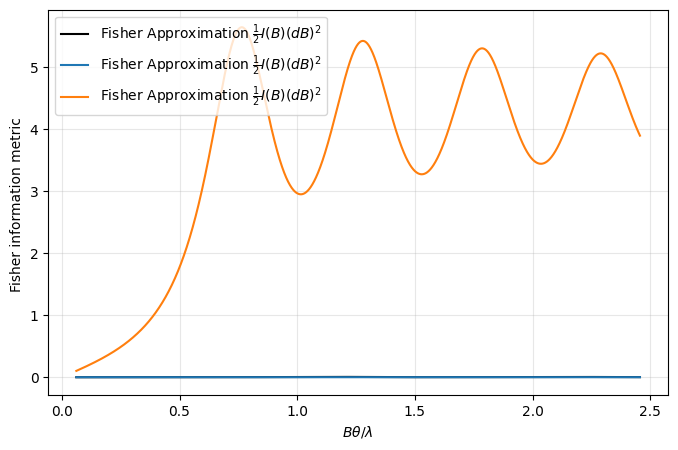

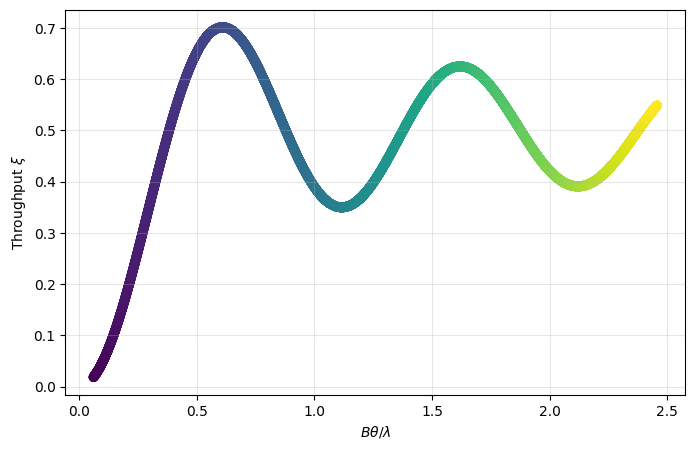

In [17]:

# 1. Grid setup
phi = np.linspace(0, np.pi, 400)
B_vals = np.linspace(1, 40, 10000)
dB = B_vals[1] - B_vals[0]
mid_B = 0.5 * (B_vals[1:] + B_vals[:-1])

# 2. Compute normalized distribution y
invariant = B_vals[None, :] * sep_planet_rad / lambda_ref
invariant_mid = mid_B * sep_planet_rad / lambda_ref
d_inv = invariant_mid[1] - invariant_mid[0]
y = np.sin(np.pi * invariant * np.sin(phi)[:, None]) ** 2 / np.pi
norm_y = trapezoid(y=y, x=phi, axis=0) #* np.pi
y /= norm_y  # P(phi; B)
y_mean = np.mean(y, axis = 0)




# =============== Plot of Signals ====================

N = 100
fig, ax = plt.subplots(figsize = (8,4))
norm = colors.Normalize(vmin=min(B_vals), vmax=max(B_vals))
cmap = cm.viridis

for i in range(N):
    j = int(y.shape[1] * i / N)
    color = cmap(norm(B_vals[j]))
    ax.plot(phi, y[:, j], color=color, alpha=0.5)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label(r"$B\theta / \lambda$")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$T(\phi; B\theta / \lambda)$")
plt.show()



# =========== Distance between neighbouring distributions =============

# scalar product
square_norm = (trapezoid(y=y*y, x=phi, axis=0))
prod = np.arccos(trapezoid(y=y[:, :-1] *y[:, 1:], x=phi, axis=0) / np.sqrt(square_norm[:-1] * square_norm[1:]) )
#prod /= np.max(prod)
#prod_angle = np.arcsin(prod)

# scalar product of mean substrated distributions
square_norm_mean = (trapezoid(y=(y - y_mean)*(y - y_mean), x=phi, axis=0))
prod_mean =  np.arccos(trapezoid(y=(y[:, :-1] - y_mean[:-1])*(y[:, 1:]-y_mean[1:]), x=phi, axis=0) / np.sqrt(square_norm_mean[:-1] * square_norm_mean[1:]) ) / d_inv # equals sqrt(d^2 NCC / d inv^2)
#prod_mean /= np.max(prod_mean)
#prod_mean_angle = np.arcsin(prod_mean)


# Direct KL divergence computation: D_KL( P(B + dB) || P(B) )
eps = 1e-12  # prevent log(0)
diff = np.log((y[:, 1:] )**y[:, 1:]  / (y[:, :-1] )**y[:, 1:] )
kl_divergence = trapezoid(y=diff, x=phi, axis=0)



# 4. Fisher Information prediction: 0.5 * (dB)^2 * I(B)
# d(log y)/dB = (1/y) * dy/dB
dy_dB = (y[:, 1:] - y[:, :-1]) / dB
mid_y = 0.5 * (y[:, 1:] + y[:, :-1])
fisher_integrand = (dy_dB**2) / (mid_y + eps)

fisher_info = trapezoid(y=fisher_integrand, x=phi, axis=0)
kl_theoretical = 0.5 * (dB**2) * fisher_info
kl_theoretical /=np.max(kl_theoretical)


# 5. Plotting
fig, ax = plt.subplots(figsize=(8, 5))
kl_smooth = make_smoothing_spline(invariant_mid, 5000*kl_divergence, lam=0.01)(invariant_mid)
ax.plot(invariant_mid, kl_smooth,  label=r"Fisher Approximation $\frac{1}{2} I(B) (dB)^2$", alpha = 1, color = 'k' )
ax.plot(invariant_mid,prod,  label=r"Fisher Approximation $\frac{1}{2} I(B) (dB)^2$" )
ax.plot(invariant_mid,prod_mean,  label=r"Fisher Approximation $\frac{1}{2} I(B) (dB)^2$")
ax.set_ylabel(r'Fisher information metric ')
ax.tick_params(axis='y')
ax.set_xlabel(r"$B\theta / \lambda$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

fig, ax2 = plt.subplots(figsize=(8, 5))
ax2.scatter(invariant, norm_y, c=invariant)

ax2.tick_params(axis='y')
ax2.set_ylabel(r'Throughput $\xi$')
ax2.set_xlabel(r"$B\theta / \lambda$")
plt.grid(True, alpha=0.3)
plt.show()





In [18]:
invariant

array([[0.0614179 , 0.06165745, 0.061897  , ..., 2.45623673, 2.45647628,
        2.45671583]])

2.42406840554768


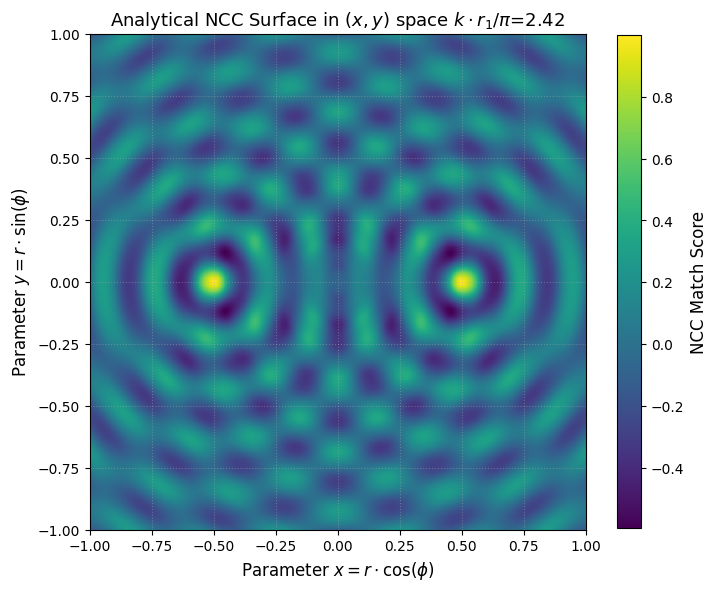

In [19]:



def compute_analytical_ncc(r1_as, phi1, R2_grid_as, PHI2_grid, k):
    """
    Computes exact NCC surface against a fixed reference template (r1, phi1).
    k = pi * B / lambda
    """
    r1 = r1_as * np.pi / 180 /3600 # [rad]
    R2_grid = R2_grid_as * np.pi / 180 /3600 # [rad]
    print(k * r1 / np.pi)

    # Angle difference between candidate phi2 and reference phi1
    delta_phi = PHI2_grid - phi1
    cos_dphi = np.cos(delta_phi)
    
    # Effective distances R_minus and R_plus
    R_minus = np.sqrt(r1**2 + R2_grid**2 - 2 * r1 * R2_grid * cos_dphi)
    R_plus  = np.sqrt(r1**2 + R2_grid**2 + 2 * r1 * R2_grid * cos_dphi)
    
    # Numerator & Denominator
    numerator = j0(2*k * R_minus) + j0(2*k * R_plus)
    
    E1 = 1.0 + j0(4 * k * r1)
    E2 = 1.0 + j0(4 * k * R2_grid)
    denominator = np.sqrt(E1 * E2)
    
    return numerator / denominator

# --- Parameters Setup ---
k =  np.pi * baseline / lambda_ref 

# Reference template position in polar coordinates
r1 = 0.5
phi1 = 0*np.pi / 4  # 45 degrees

# Map reference point to Cartesian for plotting
x1 = r1 * np.cos(phi1)
y1 = r1 * np.sin(phi1)

# Parameter space grid in Cartesian space (x, y)
max_r = r1*2
grid_points = 400
x_vals = np.linspace(-max_r, max_r, grid_points)
y_vals = np.linspace(-max_r, max_r, grid_points)
X, Y = np.meshgrid(x_vals, y_vals)

# Parametrize r2 and phi2 from X and Y
R2 = np.sqrt(X**2 + Y**2)
PHI2 = np.arctan2(Y, X)

# --- Compute Exact NCC Surface ---
ncc_surface = compute_analytical_ncc(r1, phi1, R2, PHI2, k)

# --- Plotting 2D Spatial Circular Image ---
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(ncc_surface, 
    extent=[-max_r, max_r, -max_r, max_r], 
    origin='lower',  cmap='viridis')


# Formatting
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('NCC Match Score', fontsize=12)

ax.set_title(fr'Analytical NCC Surface in $(x, y)$ space $k \cdot r_1 / \pi $={round(k*r1 / 180 /3600 ,2)}', fontsize=13)
ax.set_xlabel(r'Parameter $x = r \cdot \cos(\phi)$', fontsize=12)
ax.set_ylabel(r'Parameter $y = r \cdot \sin(\phi)$', fontsize=12)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.4)



In [20]:
def analytic_curvatures_grid(r0_grid_as, B_grid, lam=lambda_ref, kmax=None):
    r0_grid = r0_grid_as * np.pi / 180 / 3600  # [rad]
    R0, Bg = np.meshgrid(r0_grid, B_grid, indexing="ij")  # (nr, nB)
    k = np.pi * Bg / lam
    x0 = 4 * k * R0  # (nr, nB)
    J0 = jv(0, x0)
    J1 = jv(1, x0)
    A0 = 1 + J0

    kappa_t = k * J1 / (R0 * A0) - 2 * k**2 / A0
    kappa_r = 2 * k**2 * (2 * J0 -1) / A0 + 4* (k*J1/A0)**2 - k*J1 / (R0 * A0)

    return kappa_r, kappa_t

# ---------------------------------------------------------------
# Numerical NCC (used only to verify the analytic formulas)
# ---------------------------------------------------------------
def x_signal(r_as, phi, t, B, lam=lambda_ref):
    r = r_as * np.pi / 180 / 3600  # [rad]
    A = np.pi * B * r / lam
    return np.sin(A * np.sin(t + phi)) ** 2


def ncc_numeric(r0_as, phi0, r_as, phi, t, B, lam=lambda_ref):
    x0 = x_signal(r0_as, phi0, t, B, lam)
    x1 = x_signal(r_as, phi, t, B, lam)
    u0 = x0 - x0.mean()
    u1 = x1 - x1.mean()
    return (u0 @ u1) / (np.linalg.norm(u0) * np.linalg.norm(u1))


def numeric_curvatures(r0_as, phi0, B, lam=lambda_ref, N=4000, h_r=1e-4, h_phi=1e-3, case = None):
    t = np.linspace(0, 2 * np.pi, N, endpoint=False)
    f = lambda r_as, phi: ncc_numeric(r0_as, phi0, r_as, phi, t, B, lam)
    f0 = f(r0_as, phi0) # must be equal to 1
    H_rr = (f(r0_as + h_r, phi0) - 2 * f0 + f(r0_as - h_r, phi0)) / h_r ** 2
    #H_phiphi = (f(r0_as, phi0 + h_phi) - 2 * f0 + f(r0_as, phi0 - h_phi)) / h_phi ** 2
    if(case == 'angular'):
        H_phiphi = (f(r0_as, phi0 + h_phi) - 2 * f0 + f(r0_as, phi0 - h_phi)) / h_phi ** 2
    else:
        dr = r0_as *(1 - np.cos(h_phi))
        H_phiphi = (f(r0_as + dr, phi0 + h_phi) - 2 * f0 + f(r0_as + dr, phi0 - h_phi)) / (r0_as * h_phi) ** 2
    H_rphi = (
        f(r0_as + h_r, phi0 + h_phi)
        - f(r0_as + h_r, phi0 - h_phi)
        - f(r0_as - h_r, phi0 + h_phi)
        + f(r0_as - h_r, phi0 - h_phi)
    ) / (4 * h_r * h_phi)
    return H_rr, H_phiphi, H_rphi


def kappa_pearson(r1_as, Baselines, lam=lambda_ref):
    """Radial and tangential curvature (kappa_r, kappa_t) of the Pearson
    correlation peak at radius r1, wavenumber k."""
    r = r1_as * np.pi / 180 / 3600  # [rad]
    r1, B = np.meshgrid(r, Baselines, indexing="ij")  # (nr, nB)
    k = np.pi * B / lam
    x0 = 2 * k * r1
    y0 = 4 * k * r1
    P0, P1 = j0(x0), j1(x0)
    Q0, Q1 = j0(y0), j1(y0)
    V1 = (1 + Q0) / 2 - P0**2   # Var(f) at this r1
 
    kappa_t = (k * Q1 / (2 * r1) - k**2) / V1
 
    num_r = (8*P0**2*Q0*k**2*r1 - 2*P0**2*Q1*k - 4*P0**2*k**2*r1
             + 16*P0*P1*Q1*k**2*r1 - 8*P1**2*Q0*k**2*r1 - 8*P1**2*k**2*r1
             - 4*Q0**2*k**2*r1 + Q0*Q1*k - 2*Q0*k**2*r1 - 4*Q1**2*k**2*r1
             + Q1*k + 2*k**2*r1)
    den_r = r1 * (2*P0**2 - Q0 - 1) * (2 * V1)
    kappa_r = num_r / den_r
    return kappa_r / (3600*180/np.pi)**2, kappa_t / (3600*180/np.pi)**2 # [as^-2]




Text(0, 0.5, '$\\sigma_r / r$')

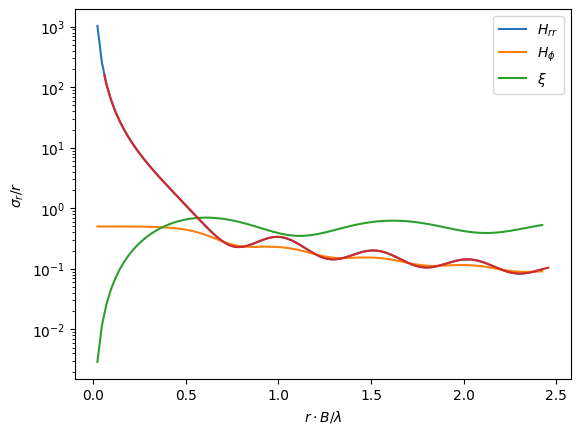

In [21]:
rB = np.linspace(0.05, 5, 100)
H_rr_a, H_phi_a = kappa_pearson(rB, 1, lam=lambda_ref)
plt.plot(rB/lambda_ref *np.pi/180/3600, 1/np.sqrt(-H_rr_a[:,0]) / rB, label=r"$H_{rr}$")
plt.plot(rB/lambda_ref *np.pi/180/3600, 1/np.sqrt(-H_phi_a[:,0]) / rB, label=r"$H_{\phi}$")

t = np.linspace(0, 2*np.pi, 1000)
xs = np.zeros((len(rB), len(t)))
for i, r in enumerate(rB):
    xs[i, :] = x_signal(r, 0, t, 1, lam=lambda_ref)
throughput = np.mean(xs, axis=1)
plt.plot(rB/lambda_ref *np.pi/180/3600, throughput, label=r"$\xi$")

plt.plot(invariant_mid, 1/prod_mean/invariant_mid)


plt.legend()
plt.yscale("log")
plt.xlabel(r"$r \cdot B / \lambda$")
plt.ylabel(r"$\sigma_r / r$")

In [26]:
print(np.max(throughput))
inv_at_max_throughput = rB[np.argmax(throughput)] *np.pi/180/3600/lambda_ref

0.7006203170693861


In [27]:
inv_at_max_throughput

0.6060171013869201

In [23]:
derivs = np.zeros((len(r0_grid_as),3))
for i in range(len(r0_grid_as)):

    derivs[i,:] = numeric_curvatures(r0_grid_as[i], 0, 5, h_r=1e-3, h_phi=1e-5)

H_rr_a, H_phi_a = kappa_pearson(r0_grid_as/3, 15)

#plt.plot(r0_grid_as, 1/np.sqrt(-derivs[:,0])/ r0_grid_as,label = 'radial numeric')
plt.plot(r0_grid_as, 1/np.sqrt(-derivs[:,1])  ,label = 'tangential numeric')
plt.plot(r0_grid_as, 3*1/np.sqrt(-H_phi_a[:,0])  , "--", label = 'tangential pearson')
plt.xlabel('r0 [as]')
plt.ylabel(r'$\sigma_\phi $')
plt.legend()
plt.show()

NameError: name 'r0_grid_as' is not defined

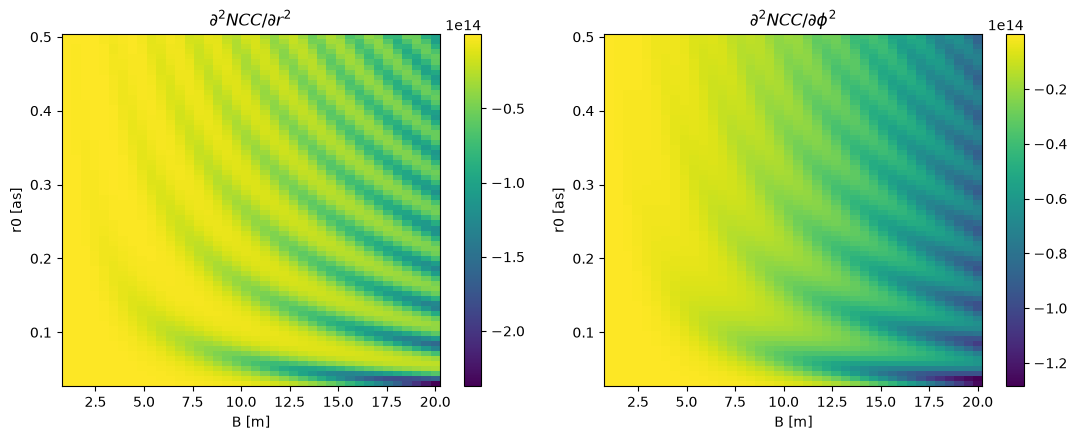

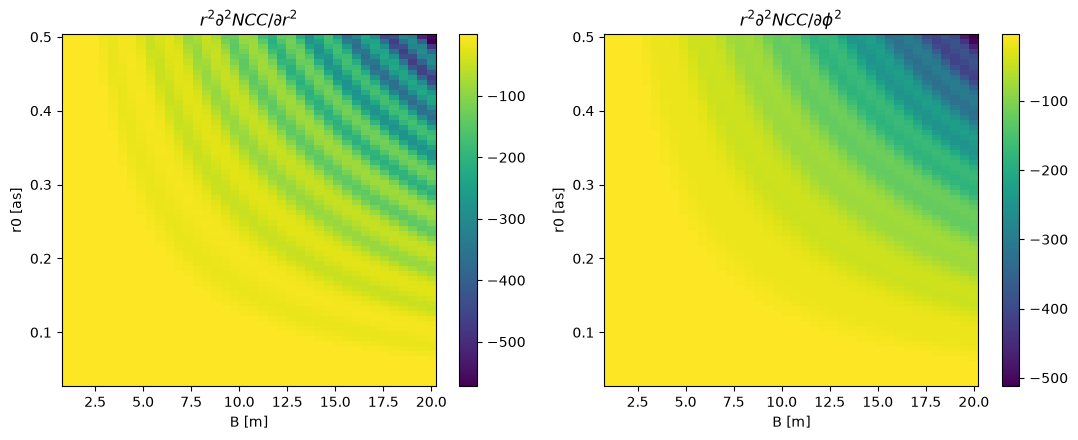

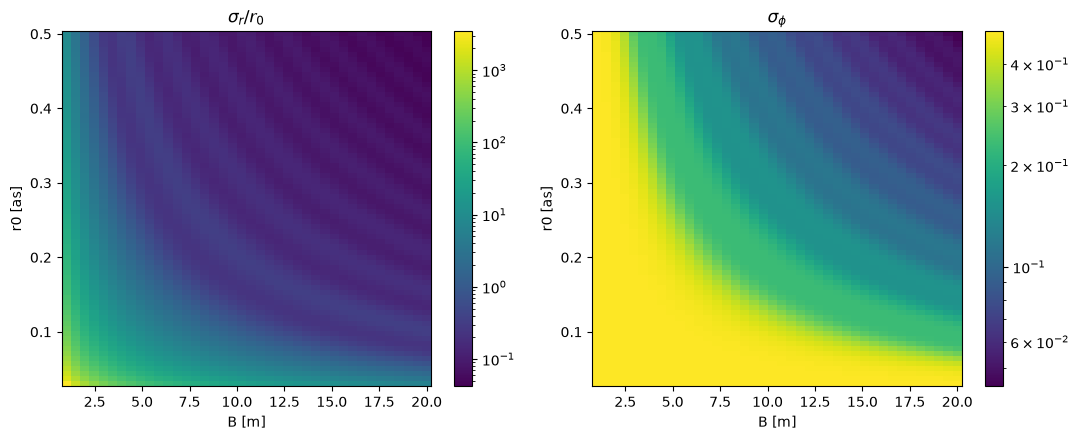

In [ ]:
# ---------------------------------------------------------------
# Grid sweep
# ---------------------------------------------------------------


r0_grid_as = np.linspace(0.03, 0.5, 70)
B_grid = np.linspace(1, 20, 40) 

H_rr_grid, H_phi_grid = analytic_curvatures_grid(r0_grid_as, B_grid)

rows = []
for i, r0 in enumerate(r0_grid_as):
    for j, B in enumerate(B_grid):
        rows.append((r0, B, H_rr_grid[i, j], H_phi_grid[i, j]))


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, grid, title in zip(
    axes,
    [H_rr_grid, H_phi_grid],
    [r"$\partial^2 NCC/\partial r^2$", r"$\partial^2 NCC/\partial \phi^2$"],
):
    im = ax.pcolormesh(B_grid, r0_grid_as, grid, shading="auto")
    ax.set_xlabel("B [m]")
    ax.set_ylabel("r0 [as]")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("ncc_curvature_grid.png", dpi=150)



H_rr_a, H_phi_a = kappa_pearson(r0_grid_as, B_grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, grid, title in zip(
    axes,
    [H_rr_a * r0_grid_as[:,None]**2, H_phi_a * r0_grid_as[:,None]**2],
    [r"$r^2 \partial^2 NCC/\partial r^2$", r"$r^2 \partial^2 NCC/\partial \phi^2$"],
):
    im = ax.pcolormesh(B_grid, r0_grid_as, grid, shading="auto")
    ax.set_xlabel("B [m]")
    ax.set_ylabel("r0 [as]")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("ncc_curvature_grid.png", dpi=150)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, grid, title in zip(
    axes,
    [1/np.sqrt(-H_rr_a) / r0_grid_as[:,None], 1/np.sqrt(-H_phi_a) / r0_grid_as[:,None]],
    [r"$\sigma_r / r_0$", r"$\sigma_\phi $"],
):
    im = ax.pcolormesh(B_grid, r0_grid_as, grid, shading="auto", norm = LogNorm())
    ax.set_xlabel("B [m]")
    ax.set_ylabel("r0 [as]")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("ncc_curvature_grid.png", dpi=150)









In [ ]:
# ------------------------------------------------------------
# Verification: compare analytic vs numeric Hessian at one point
# ------------------------------------------------------------
r0_test, B_test, phi0_test = 0.2, 10, 0.4
H_rr_a, H_phi_a = analytic_curvatures_grid(r0_test, B_test)
H_rr_n, H_phi_n, H_rphi_n = numeric_curvatures(r0_test, phi0_test, B_test, h_r=1e-7, h_phi=1e-5)

print(f"\nVerification at r0={r0_test}, B={B_test}, phi0={phi0_test}")
print(f"  H_rr:     analytic={H_rr_a[0,0]: .6f}   numeric={H_rr_n: .6f}")
print(f"  H_phiphi: analytic={H_phi_a[0,0]: .6f}   numeric={H_phi_n: .6f}")
print(f"  H_rphi:   analytic=0.000000   numeric={H_rphi_n: .6e}  (should be ~0)")


Verification at r0=0.2, B=10, phi0=0.4
  H_rr:     analytic=-12912365277109.076172   numeric=-225.475194
  H_phiphi: analytic=-18767700917951.066406   numeric=-467.553607
  H_rphi:   analytic=0.000000   numeric= 0.000000e+00  (should be ~0)


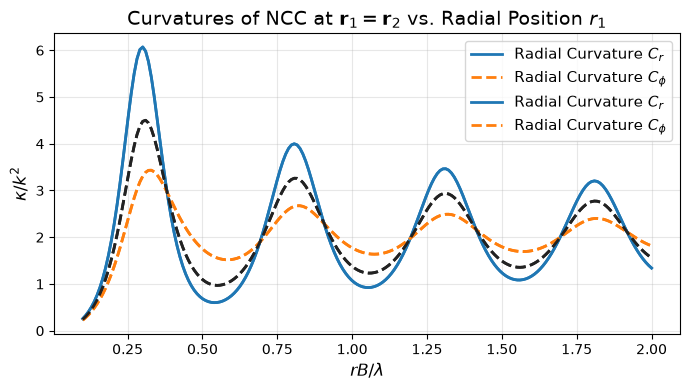

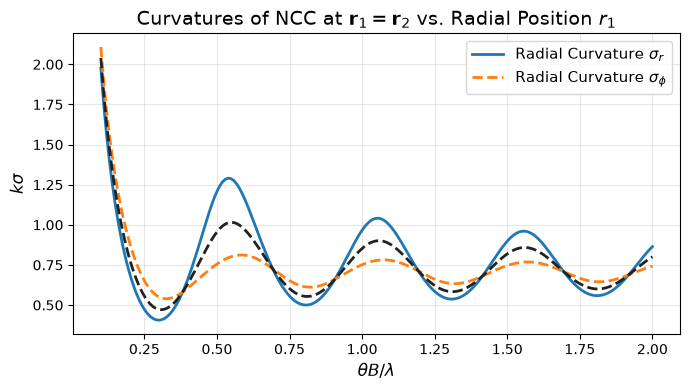

In [ ]:


def compute_curvatures(r1, k=1.0):
    """
    Computes radial curvature Cr and azimuthal curvatures Cphi and Cs1
    for NCC as a function of radial coordinate r1.
    """
    kr1 = k * r1
    arg = 4 * kr1
    
    # Bessel terms
    J0_val = j0(arg)
    J1_val = j1(arg)
    
    denom = 1.0 + J0_val # A0
    
    # Azimuthal curvature wrt angle delta_phi
    C_rphi =  k * J1_val / (r1 * denom) - 2*k**2 / denom
    C_r = - k * J1_val / (r1 * denom) + 4 * (k * J1_val / denom)**2 + 2 * k**2 *(2*J0_val -1)/denom
    
    
    return C_r, C_rphi # scale with k**2 more or less

B = 5.0          # Bandwidth factor
lam = 4e-6        # Wavelength
k =  np.pi* B / lam 


# Radial distance range (from 0 to 3 wavelengths)


# --- Plotting ---
plt.figure(figsize=(7, 4))
k/=1

r1_vals =  np.linspace(0.1,2, 200)  * np.pi / k
C_r, C_phi = compute_curvatures(r1_vals, k=k)
sig_r, sig_phi = np.sqrt(-1/C_r), np.sqrt(-1/C_phi)

plt.plot(r1_vals*k/np.pi, -C_r/k**2, label=r'Radial Curvature $C_r$', color='#1f77b4', linewidth=2)
plt.plot(r1_vals*k/np.pi, -C_phi/k**2, label=r'Radial Curvature $C_\phi$', color='#ff7f0e', linewidth=2, linestyle='--')
plt.plot(r1_vals*k/np.pi, np.sqrt(C_r*C_phi)/k**2,  color='#222222', linewidth=2, linestyle='--') # does not change by changing k

k/=1
#r1_vals =  np.linspace(0.1,2, 200)  * np.pi / k
C_r, C_phi = compute_curvatures(r1_vals, k=k)
sig_r, sig_phi = np.sqrt(-1/C_r), np.sqrt(-1/C_phi)

plt.plot(r1_vals*k/np.pi, -C_r/k**2, label=r'Radial Curvature $C_r$', color='#1f77b4', linewidth=2)
plt.plot(r1_vals*k/np.pi, -C_phi/k**2, label=r'Radial Curvature $C_\phi$', color='#ff7f0e', linewidth=2, linestyle='--')
plt.plot(r1_vals*k/np.pi, np.sqrt(C_r*C_phi)/k**2,  color='#222222', linewidth=2, linestyle='--') # does not change by changing k


plt.title(r'Curvatures of NCC at $\mathbf{r}_1 = \mathbf{r}_2$ vs. Radial Position $r_1$', fontsize=14)
plt.xlabel(r'$r  B  / \lambda$', fontsize=12)
plt.ylabel(r'$\kappa /k^2 $', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()




# --- Plotting ---
plt.figure(figsize=(7, 4))

# Plot Radial Curvature C_r
plt.plot(r1_vals*k/np.pi, k*sig_r, label=r'Radial Curvature $\sigma_r$', color='#1f77b4', linewidth=2)
plt.plot(r1_vals*k/np.pi, k*sig_phi, label=r'Radial Curvature $\sigma_\phi$',  color='#ff7f0e', linewidth=2, linestyle='--')
plt.plot(r1_vals*k/np.pi, k*np.sqrt(sig_r*sig_phi),  color='#222222', linewidth=2, linestyle='--')
plt.title(r'Curvatures of NCC at $\mathbf{r}_1 = \mathbf{r}_2$ vs. Radial Position $r_1$', fontsize=14)
plt.xlabel(r'$\theta  B  / \lambda$', fontsize=12)
plt.ylabel(r'$k \sigma$', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()





In [ ]:
k

3926990.8169872416

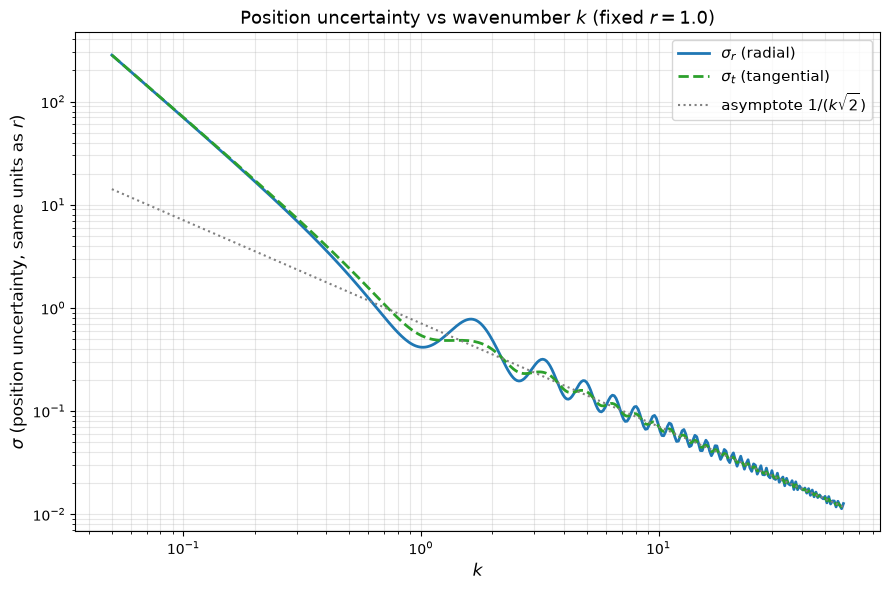

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, j1
 
 
def compute_sigmas(r, k):
    """Radial/tangential position-uncertainty (1-sigma) of the NCC peak
    at target radius r, wavenumber k."""
    x0 = 4 * k * r
    J0_val = j0(x0)
    J1_val = j1(x0)
    A0 = 1.0 + J0_val
 
    C_r = (2 * k**2 * (2 * J0_val - 1) / A0
           + 4 * (k * J1_val / A0)**2
           - k * J1_val / (r * A0))
    C_t = k * J1_val / (r * A0) - 2 * k**2 / A0
 
    sigma_r = np.sqrt(-1.0 / C_r)
    sigma_t = np.sqrt(-1.0 / C_t)
    return sigma_r, sigma_t
 
 
# --- Parameters ---
r = 1.0                                   # fixed target radius
k_vals = np.logspace(np.log10(0.05), np.log10(60), 400)
 
sigma_r, sigma_t = compute_sigmas(r, k_vals)
isotropic_asymptote = 1.0 / (k_vals * np.sqrt(2))   # sigma -> 1/(k*sqrt2) as k -> inf
 
# --- Plot ---
plt.figure(figsize=(9, 6))
plt.loglog(k_vals, sigma_r, label=r'$\sigma_r$ (radial)', color='#1f77b4', linewidth=2)
plt.loglog(k_vals, sigma_t, label=r'$\sigma_t$ (tangential)', color='#2ca02c', linewidth=2, linestyle='--')
plt.loglog(k_vals, isotropic_asymptote, label=r'asymptote $1/(k\sqrt{2})$',
           color='gray', linewidth=1.5, linestyle=':')
 
plt.title(f'Position uncertainty vs wavenumber $k$ (fixed $r={r}$)', fontsize=13)
plt.xlabel('$k$', fontsize=12)
plt.ylabel(r'$\sigma$ (position uncertainty, same units as $r$)', fontsize=12)
plt.grid(True, which='both', alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('sigma_vs_k.png', dpi=150)
plt.show()

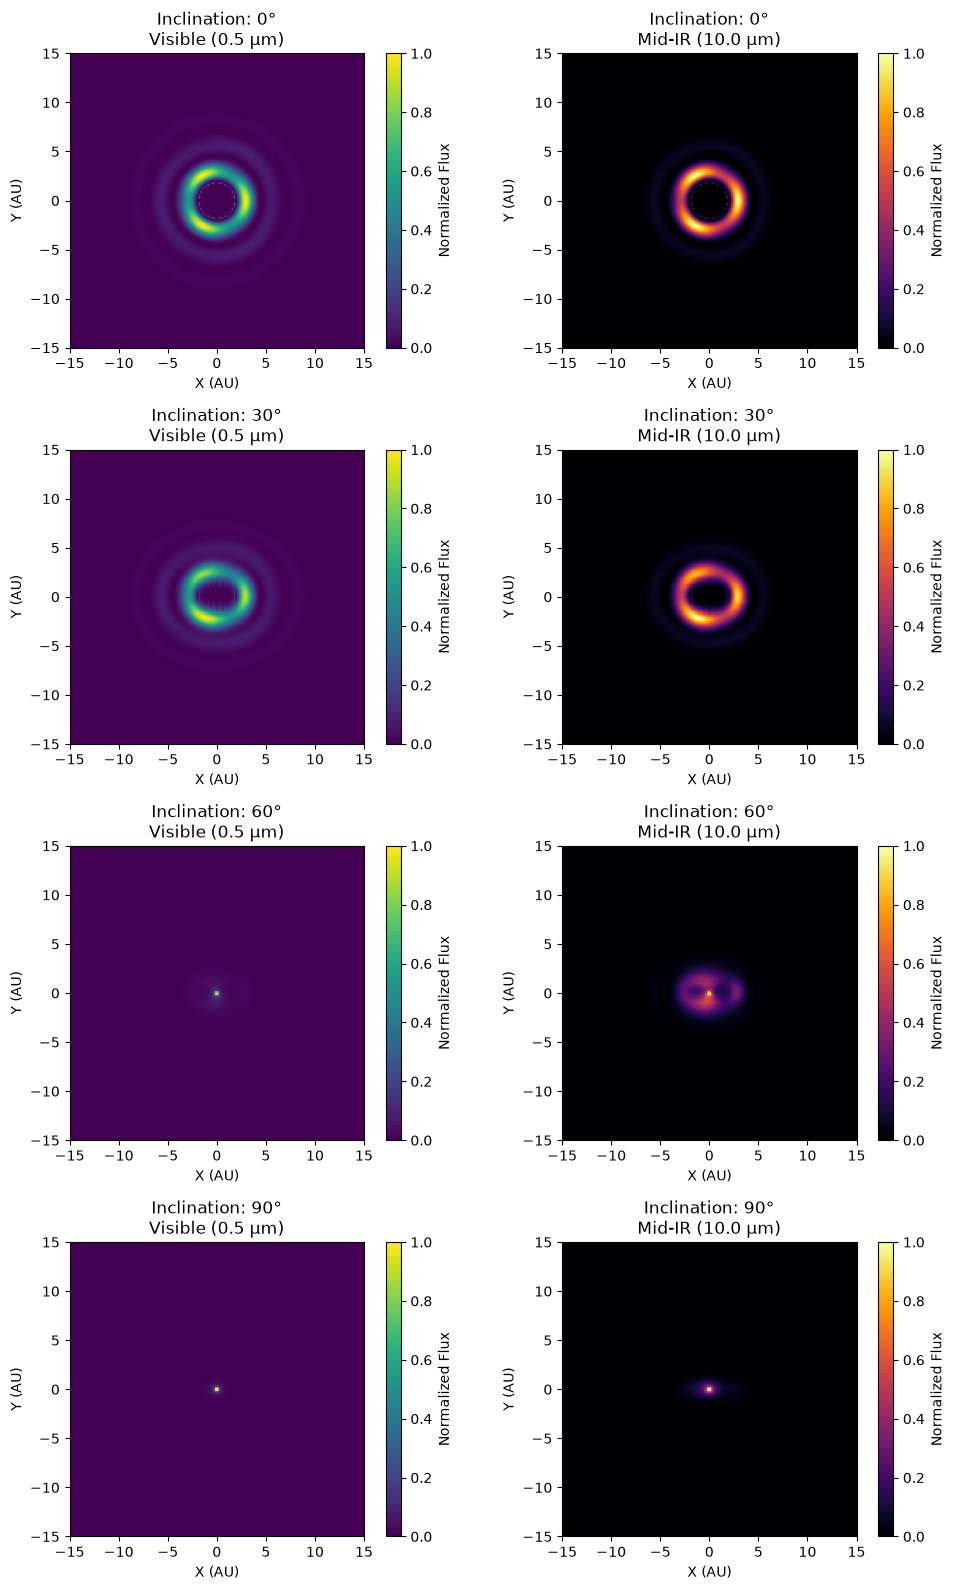

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jn  # Bessel function of first kind

# 1. Setup 3D Grid Parameters (X, Y, Z)
grid_res = 160             # Resolution of the 3D cube
box_size = 15.0            # Boundaries from -15 to +15 AU
axis = np.linspace(-box_size, box_size, grid_res)
X, Y, Z = np.meshgrid(axis, axis, axis, indexing='ij')

# 2. Generate the Base 3D Physical Disk Structure
def generate_3d_disk_density(clumpy=True):
    # Convert flat coordinates to cylindrical coordinates (r, theta, z)
    R_cyl = np.sqrt(X**2 + Y**2) + 1e-6
    Theta = np.arctan2(Y, X)
    
    # Radial structural profile using a 0th-order Bessel function
    k_radial = 1.2
    radial_profile = (jn(0, k_radial * R_cyl))**2 * np.exp(-R_cyl / 6.0)
    radial_profile[R_cyl < 1.8] = 0  # Clear out inner stellar zone
    
    # Structural Clumps using a 3rd-order Bessel-Fourier term
    if clumpy:
        m_clumps = 3
        clump_factor = jn(m_clumps, k_radial * R_cyl) * np.cos(m_clumps * Theta)
        density_profile = radial_profile * (1.0 + 0.8 * clump_factor)
    else:
        density_profile = radial_profile

    # Vertical distribution profile (Gaussian disk scale height H = 0.8 AU)
    H = 0.8 
    vertical_profile = np.exp(-0.5 * (Z / H)**2)
    
    # Combine into a final 3D Density Grid
    return np.clip(density_profile * vertical_profile, 0, None)

# 3. Rotate the 3D Grid & Integrate Along the Line of Sight
def project_disk_at_inclination(density_3d, inclination_deg):
    angle_rad = np.radians(inclination_deg)
    
    # Define standard rotation matrix coordinates around X-axis
    # Rotates the viewing coordinates to look through the cube at an angle
    Y_rot = Y * np.cos(angle_rad) - Z * np.sin(angle_rad)
    Z_rot = Y * np.sin(angle_rad) + Z * np.cos(angle_rad)
    
    # Map coordinates from grid units to array index units
    idx_X = ((X + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Y = ((Y_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Z = ((Z_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    
    # Keep indices strictly inside array boundaries
    mask = (idx_Y >= 0) & (idx_Y < grid_res) & (idx_Z >= 0) & (idx_Z < grid_res)
    
    # Map original density values into the newly rotated 3D grid spatial array
    rotated_density = np.zeros_like(density_3d)
    rotated_density[mask] = density_3d[idx_X[mask], idx_Y[mask], idx_Z[mask]]
    
    # Numerical line-of-sight integration: Collapse the Z axis to get a 2D image
    integrated_2d_density = np.sum(rotated_density, axis=2)
    return integrated_2d_density

# 4. Multi-Wavelength Flux Calculations
def calculate_wavelength_flux(density_2d, wavelength_um):
    # Set up a 2D distance map from the central stellar core
    X_2d, Y_2d = np.meshgrid(axis, axis, indexing='ij')
    R_2d = np.sqrt(X_2d**2 + Y_2d**2) + 1e-6
    
    # Radial profile of dust grain temperature: drops with distance (T ~ R^-0.5)
    T_profile = 280.0 * (R_2d / 5.0)**(-0.5)
    
    if wavelength_um < 1.0:
        # Visible Light: Dominated by scattered stellar flux (falls off as 1/R^2)
        flux = density_2d * (1.0 / R_2d**2)
    else:
        # Infrared Light: Thermal dust emission via Planck's Law approximation
        h, c, kB = 6.626e-34, 3.0e8, 1.38e-23
        freq = c / (wavelength_um * 1e-6)
        exponent = (h * freq) / (kB * T_profile)
        blackbody = (2.0 * h * freq**3 / c**2) / (np.exp(np.clip(exponent, 0, 700)) - 1.0)
        flux = density_2d * blackbody
        
    return flux / np.max(flux)  # Normalized output 

# 5. Generate Simulation Grid Matrix (Angles: 0, 30, 60, 90)
inclinations = [0, 30, 60, 90]
wavelengths = {"Visible (0.5 µm)": 0.5, "Mid-IR (10.0 µm)": 10.0}

# Pre-generate our 3D master clumpy disk array
master_3d_disk = generate_3d_disk_density(clumpy=True)

fig, axes = plt.subplots(4, 2, figsize=(10, 16))
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for row_idx, inc in enumerate(inclinations):
    # Perform 3D line-of-sight rotation calculation for this specific angle
    density_surface = project_disk_at_inclination(master_3d_disk, inc)
    
    for col_idx, (wave_name, wave_val) in enumerate(wavelengths.items()):
        ax = axes[row_idx, col_idx]
        
        # Calculate localized physical wavelength emission properties
        flux_map = calculate_wavelength_flux(density_surface, wave_val)
        
        # Plot styling matrix
        cmap = "viridis" if wave_val < 1.0 else "inferno"
        im = ax.imshow(flux_map.T, extent=[-box_size, box_size, -box_size, box_size], 
                       cmap=cmap, origin='lower')
        
        ax.set_title(f"Inclination: {inc}°\n{wave_name}")
        ax.set_xlabel("X (AU)")
        ax.set_ylabel("Y (AU)")
        fig.colorbar(im, ax=ax, label="Normalized Flux")

plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Intensity Pattern (FFT of Aperture)')

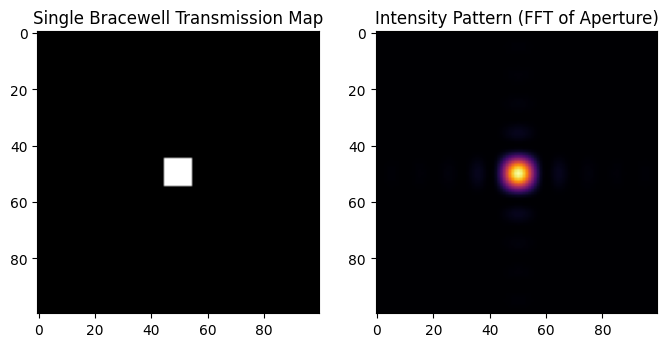

In [ ]:
# Single Bracewell Transmission Map

Aperture = np.zeros((100, 100))
Aperture[45:55, 45:55] = 1
Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2


fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray')
ax[0].set_title('Single Bracewell Transmission Map')
#ax[0].colorbar()
ax[1].imshow(Intensity, cmap='inferno')
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
#ax[1].colorbar()



(-2.0, 2.0)

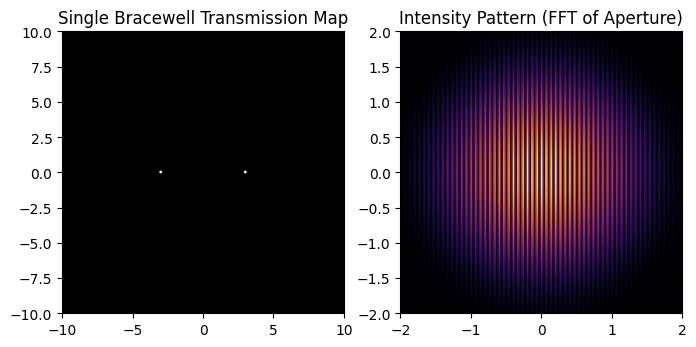

In [ ]:
# Single Bracewell Transmission Map
x = np.linspace(-10, 10, 1000)
y = np.linspace(-10, 10, 1000)
X, Y = np.meshgrid(x, y)
Aperture = np.zeros_like(X)
Aperture[np.sqrt((X-3)**2 + Y**2) < 0.1] = 1
Aperture[np.sqrt((X+3)**2 + Y**2) < 0.1] = 1

Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2

fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray', extent=[-10, 10, -10, 10])
ax[0].set_title('Single Bracewell Transmission Map')
ax[1].imshow(Intensity, cmap='inferno', extent=[-10, 10, -10, 10])
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
ax[1].set_xlim([-2, 2])
ax[1].set_ylim([-2, 2])

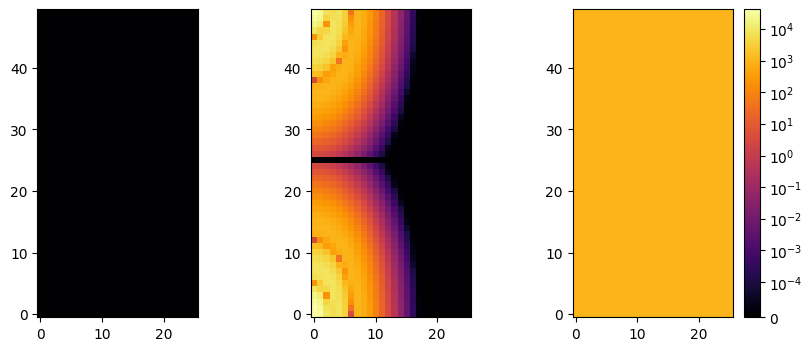

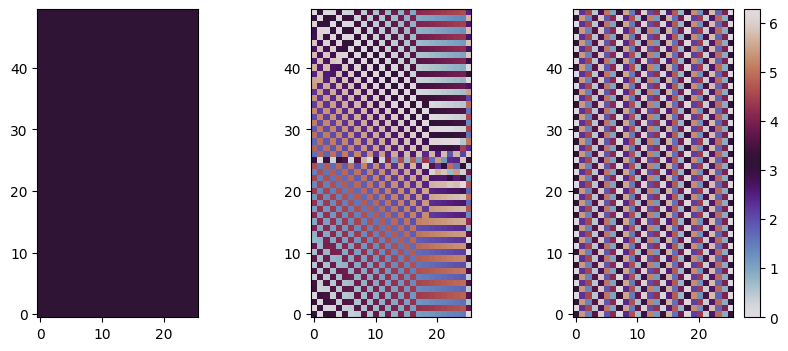

In [ ]:
IM_star_fft = np.fft.rfft2(IM_star)
IM_exozodi_fft = np.fft.rfft2(IM_exozodi)
IM_planet_fft = np.fft.rfft2(IM_planet)

vmin = min(np.min(np.abs(IM_star_fft)), np.min(np.abs(IM_exozodi_fft)), np.min(np.abs(IM_planet_fft)))
vmax = max(np.max(np.abs(IM_star_fft)), np.max(np.abs(IM_exozodi_fft)), np.max(np.abs(IM_planet_fft)))
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(np.abs(IM_star_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001))
ax[1].imshow(np.abs(IM_exozodi_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001)) 
ax[2].imshow(np.abs(IM_planet_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001)) 
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

vmin = min(np.min(np.abs(IM_star_fft)), np.min(np.abs(IM_exozodi_fft)), np.min(np.abs(IM_planet_fft)))
vmax = max(np.max(np.abs(IM_star_fft)), np.max(np.abs(IM_exozodi_fft)), np.max(np.abs(IM_planet_fft)))
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(np.angle(IM_star_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi)
ax[1].imshow(np.angle(IM_exozodi_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi) 
ax[2].imshow(np.angle(IM_planet_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi) 
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

In [ ]:
'''N = len(t)
freq_full = np.fft.rfftfreq(N, d=t[1]-t[0])
freq = np.abs(freq_full)

def compute_fft(signal):
    signal_fft = np.fft.rfft(signal, axis = 1)
    amp = 2.0 / N * np.abs(signal_fft) 
    phase = np.angle(signal_fft)
    return amp, phase


amp_p, phase_p = compute_fft(signal_planet)
amp_ez, phase_ez = compute_fft(signal_exozodi)
amp_both, phase_both = compute_fft(signal_both)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
vmin = min(np.min(amp_p), np.min(amp_ez), np.min(amp_both))
vmax = max(np.max(amp_p), np.max(amp_ez), np.max(amp_both))

ax[0].imshow(amp_p,  extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[1].imshow(amp_ez,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[2].imshow(amp_both,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[0].set_title('Amplitude with Planet')
ax[1].set_title('Amplitude with Exozodi')
ax[2].set_title('Amplitude with Both')
# add colorbar
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

vmin = min(np.min(phase_p), np.min(phase_ez), np.min(phase_both))
vmax = max(np.max(phase_p), np.max(phase_ez), np.max(phase_both))

ax[0].imshow(phase_p, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[1].imshow(phase_ez, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[2].imshow(phase_both, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[0].set_title('Phase with Planet')
ax[1].set_title('Phase with Exozodi')
ax[2].set_title('Phase with Both')
# add colorbar
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])'''



"N = len(t)\nfreq_full = np.fft.rfftfreq(N, d=t[1]-t[0])\nfreq = np.abs(freq_full)\n\ndef compute_fft(signal):\n    signal_fft = np.fft.rfft(signal, axis = 1)\n    amp = 2.0 / N * np.abs(signal_fft) \n    phase = np.angle(signal_fft)\n    return amp, phase\n\n\namp_p, phase_p = compute_fft(signal_planet)\namp_ez, phase_ez = compute_fft(signal_exozodi)\namp_both, phase_both = compute_fft(signal_both)\n\nfig, ax = plt.subplots(1, 3, figsize=(18, 4))\nvmin = min(np.min(amp_p), np.min(amp_ez), np.min(amp_both))\nvmax = max(np.max(amp_p), np.max(amp_ez), np.max(amp_both))\n\nax[0].imshow(amp_p,  extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))\nax[1].imshow(amp_ez,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))\nax[2].imshow(amp_both,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambd